
# CLUSTERING ANALYSIS
## DATASET DESCRIPTION:

The Airbnb NYC 2019 dataset contains details about Airbnb listings across New York City. The main aim of this clustering project is to group similar listings based on factors such as location, room type, price, minimum nights, reviews, host information, and availability.

##### Target Variable:

This dataset does not have a specific target variable because clustering is an unsupervised learning technique. Instead, it helps identify groups of listings that share similar characteristics.
The dataset includes both numerical and categorical features related to listing locations, room types, prices, host details, customer reviews, and availability.
**Dimension of the dataset:** 48,895 rows × 16 columns.

##  Import Required Libraries

The following libraries are used for data loading, preprocessing, clustering,
evaluation, dimensionality reduction, and visualization.

In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.cluster import KMeans, AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

##  Dataset Loading

The Airbnb dataset is loaded into a Pandas DataFrame.
The dataset is then inspected to understand its dimensions, columns,
data types, missing values, and duplicate observations.

In [12]:

df = pd.read_csv("../data/clusteringdataset.csv")

print("Dataset Shape:", df.shape)

Dataset Shape: (48895, 16)


## Dataset Preview

The first five records are displayed to understand the structure and
contents of the dataset.

In [13]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


##  Dataset Information

The data types and non-null counts of all variables are examined before
preprocessing.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

## Column Names

The column names are displayed to identify the variables available for
clustering and to determine which variables should be excluded.

##  Missing Value Analysis

Missing values are examined before clustering.
The variables `reviews_per_month` and `last_review` contain missing values.
`reviews_per_month` is used as a numerical feature and therefore requires
treatment.
`last_review` is not used as a clustering feature because it is a date
variable.

In [15]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (missing_values / len(df) * 100).round(2)
})

display(missing_table)

,Missing Values,Percentage
id,0,0.00
name,16,0.03
host_id,0,0.00
host_name,21,0.04
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00


##  Duplicate Check

Duplicate rows are checked before preparing the clustering dataset.

In [16]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


##  Feature Selection

The selected variables represent meaningful characteristics of Airbnb
listings.
Numerical features include geographical coordinates, price, minimum nights,
review activity, host listing count, and availability.
Categorical features include neighbourhood group and room type.
Identifier and free-text variables are excluded because they do not provide
meaningful numerical similarity between listings.

In [17]:
numerical_features = [
    "latitude",
    "longitude",
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

categorical_features = [
    "neighbourhood_group",
    "room_type"
]

features = numerical_features + categorical_features

X = df[features].copy()

print("Selected Features:")
print(features)

print("\nNumber of Selected Features:", len(features))
print("Clustering Data Shape:", X.shape)

Selected Features:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group', 'room_type']

Number of Selected Features: 10
Clustering Data Shape: (48895, 10)


##  Handling Missing Values

The `reviews_per_month` variable contains missing values.
For this analysis, missing review frequency is treated as zero because a
listing without recorded reviews does not have observed monthly review
activity.
The `last_review` variable is excluded from the clustering features.

In [18]:
X["reviews_per_month"] = X["reviews_per_month"].fillna(0)

print("Remaining missing values:")
print(X.isnull().sum())

Remaining missing values:
latitude                          0
longitude                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
neighbourhood_group               0
room_type                         0
dtype: int64


##  Numerical Feature Distribution

The numerical variables are examined before transformation to identify
variables with highly skewed distributions.

In [19]:
X[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,48895.0,40.728949,0.054530,40.49979,40.69010,40.72307,40.763115,40.91306
longitude,48895.0,-73.952170,0.046157,-74.24442,-73.98307,-73.95568,-73.936275,-73.71299
price,48895.0,152.720687,240.154170,0.00000,69.00000,106.00000,175.000000,10000.00000
minimum_nights,48895.0,7.029962,20.510550,1.00000,1.00000,3.00000,5.000000,1250.00000
number_of_reviews,48895.0,23.274466,44.550582,0.00000,1.00000,5.00000,24.000000,629.00000
reviews_per_month,48895.0,1.090910,1.597283,0.00000,0.04000,0.37000,1.580000,58.50000
calculated_host_listings_count,48895.0,7.143982,32.952519,1.00000,1.00000,1.00000,2.000000,327.00000
availability_365,48895.0,112.781327,131.622289,0.00000,0.00000,45.00000,227.000000,365.00000


## Feature Transformation

Several Airbnb numerical variables can contain highly skewed values,
especially price, minimum nights, review counts, host listing counts,
and availability.
A `log1p` transformation is applied to reduce the effect of extremely
large observations while preserving zero values.

In [20]:
log_features = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

for column in log_features:
    X[column] = np.log1p(X[column].clip(lower=0))

print("Log transformation completed.")

Log transformation completed.


##  Encoding and Feature Scaling

K-Means and Agglomerative Hierarchical Clustering require numerical
representations of the input features.
Categorical variables are converted using One-Hot Encoding.
Numerical variables are standardized using StandardScaler so that variables
with larger numerical ranges do not dominate distance calculations.

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X_processed = preprocessor.fit_transform(X)

print("Processed Data Shape:", X_processed.shape)

Processed Data Shape: (48895, 16)


##  Sampling for Computational Efficiency

The dataset contains 48,895 observations.
K-Means can efficiently handle a large dataset, while Agglomerative
Hierarchical Clustering requires substantially more computational resources.
Therefore, a reproducible sample of 3,000 observations is used for the
direct comparison of the two algorithms.
The same sample is used for both algorithms to maintain a consistent
comparison.

In [22]:
import numpy as np

RANDOM_STATE = 42
SAMPLE_SIZE = 3000

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(X_processed),
    size=SAMPLE_SIZE,
    replace=False
)

X_cluster = X_processed[sample_indices]
df_cluster = df.iloc[sample_indices].copy()

print("Clustering Sample Shape:", X_cluster.shape)

Clustering Sample Shape: (3000, 16)


# K-MEANS CLUSTERING

##  K-Means Algorithm

K-Means is a partition-based clustering algorithm that divides observations
into K clusters.
Each observation is assigned to the cluster with the nearest centroid.
The number of clusters, K, needs to be selected before fitting the final
model.
The Elbow Method is used to determine a suitable value of K.

In [23]:
from sklearn.cluster import KMeans

RANDOM_STATE = 42

inertia_values = []

for k in k_values:
    kmeans_model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    kmeans_model.fit(X_cluster)
    inertia_values.append(kmeans_model.inertia_)

print("Elbow calculations completed.")

Elbow calculations completed.


##  Elbow Method

The Elbow Method plots the within-cluster sum of squared distances,
represented by inertia, against the number of clusters.
The point where the reduction in inertia starts to become less significant
is considered a possible value for K.

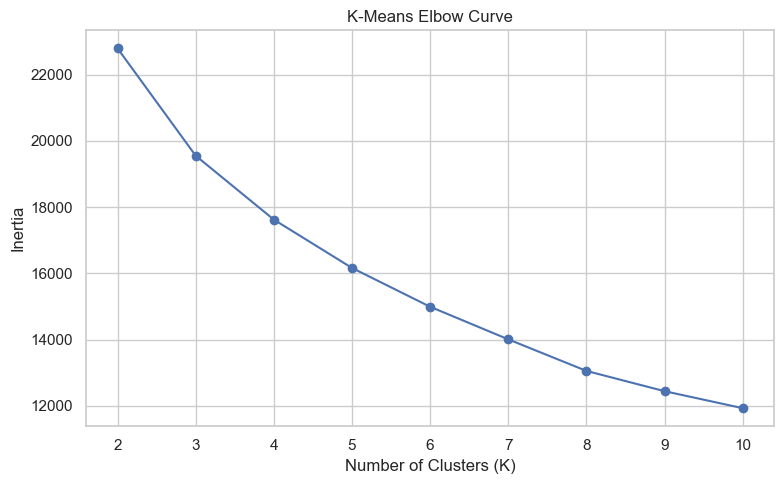

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Curve")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)

plt.tight_layout()
plt.show()


## Elbow Curve Observation

The Elbow Method helps identify a suitable number of clusters by examining the change in inertia as K increases. Inertia decreases as more clusters are introduced, although the improvement generally becomes smaller as K increases.

Based on the elbow curve, K = 3 is selected as a reasonable candidate for the K-Means model. The selection is also considered alongside the clustering evaluation metrics.

**Selected number of clusters: K = 3**

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(X_cluster, labels)

    print("K =", k, "| Silhouette Score =", round(score, 4))

K = 2 | Silhouette Score = 0.1829
K = 3 | Silhouette Score = 0.2099
K = 4 | Silhouette Score = 0.1741
K = 5 | Silhouette Score = 0.1816
K = 6 | Silhouette Score = 0.1856


##  K-Means Model

The selected number of clusters is used to train the final K-Means model.

In [26]:
K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_cluster)

print("K-Means clustering completed.")
print("Number of clusters:", K)

K-Means clustering completed.
Number of clusters: 3


##  K-Means Cluster Sizes

The number of Airbnb listings assigned to each K-Means cluster is examined
to understand the distribution of observations across the clusters.

In [28]:
kmeans_cluster_sizes = (
    pd.Series(kmeans_labels)
    .value_counts()
    .sort_index()
)

cluster_percentages = (
    kmeans_cluster_sizes / len(kmeans_labels) * 100
)

cluster_summary = pd.DataFrame({
    "Number of Listings": kmeans_cluster_sizes,
    "Percentage (%)": cluster_percentages.round(2)
})

display(cluster_summary)


,Number of Listings,Percentage (%)
0,1164,38.80
1,1624,54.13
2,212,7.07


##  K-Means Evaluation

The K-Means clusters are evaluated using three mandatory clustering metrics.

### Silhouette Score
Measures how well each observation fits within its assigned cluster
compared with other clusters.

### Davies-Bouldin Index
Measures similarity between clusters. Lower values generally indicate more
compact and separated clusters.

### Calinski-Harabasz Index
Measures the ratio between between-cluster dispersion and within-cluster
dispersion. Higher values generally indicate stronger cluster separation.

In [29]:
kmeans_silhouette = silhouette_score(
    X_cluster,
    kmeans_labels
)

kmeans_db = davies_bouldin_score(
    X_cluster,
    kmeans_labels
)

kmeans_ch = calinski_harabasz_score(
    X_cluster,
    kmeans_labels
)

kmeans_metrics = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ],
    "K-Means": [
        kmeans_silhouette,
        kmeans_db,
        kmeans_ch
    ]
})

display(kmeans_metrics.round(4))

,Metric,K-Means
0,Silhouette Score,0.2099
1,Davies-Bouldin Index,1.6399
2,Calinski-Harabasz Index,628.1446


#  PCA Visualization — K-Means

The processed dataset contains multiple dimensions because categorical
variables were converted into one-hot encoded features.
Principal Component Analysis (PCA) is used to reduce the data to two
principal components for visualization.
PCA is used only for visualization; the K-Means algorithm was trained using
the complete processed feature matrix.

In [30]:
pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_pca = pca.fit_transform(X_cluster)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Explained Variance Ratio:
[0.24228437 0.1857269 ]

Total Variance Explained: 0.428


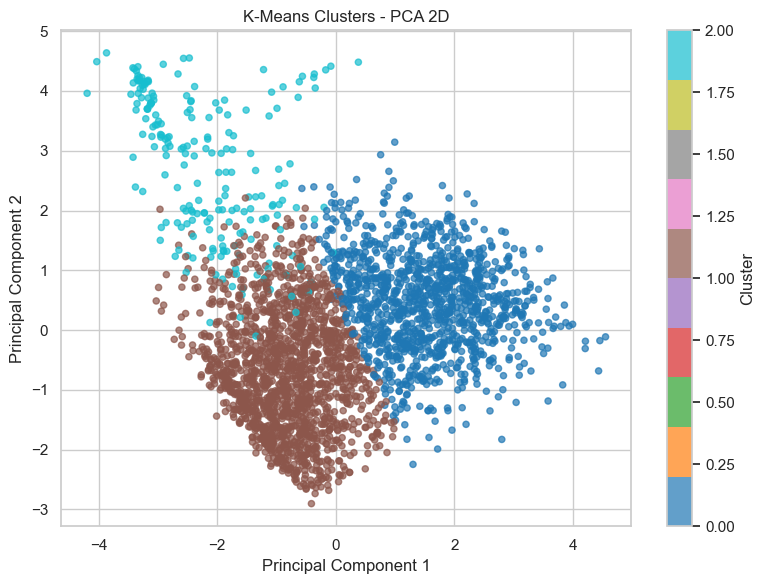

In [31]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    s=20,
    alpha=0.7
)

plt.title("K-Means Clusters - PCA 2D")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

## PCA Observation — K-Means

The PCA plot represents the K-Means clusters in two dimensions using the first two principal components. Each colour represents a different cluster assigned by the K-Means algorithm.
The first two principal components explain approximately 42.80% of the total variance in the processed dataset. Therefore, the PCA plot provides a partial view of the original feature space, and some information is lost during dimensionality reduction.
The plot should be interpreted by examining the visible separation and overlap between the coloured groups. The two-dimensional visualization alone is not sufficient to determine clustering quality.

#  Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is a bottom-up clustering algorithm.
Initially, every observation is treated as an individual cluster. Similar
clusters are then progressively merged until the required number of
clusters is reached.
Different linkage strategies define how the distance between clusters is
calculated.
The following linkage strategies are compared:

- Ward
- Complete
- Average
- Single

In [32]:
linkage_methods = [
    "ward",
    "complete",
    "average",
    "single"
]

linkage_results = []

for method in linkage_methods:

    model = AgglomerativeClustering(
        n_clusters=K,
        linkage=method
    )

    labels = model.fit_predict(X_cluster)

    linkage_results.append({
        "Linkage": method,
        "Silhouette Score": silhouette_score(
            X_cluster,
            labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_cluster,
            labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_cluster,
            labels
        )
    })

linkage_comparison = pd.DataFrame(linkage_results)

display(linkage_comparison.round(4))

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,0.1681,1.9583,500.2212
1,complete,0.1323,2.3193,165.1617
2,average,0.3144,0.7322,8.6785
3,single,0.3723,0.5427,6.3024


## Linkage Strategy Comparison

The four linkage strategies produce different cluster assignments and evaluation scores on the same processed dataset.
Ward linkage aims to minimize the increase in within-cluster variance when merging clusters. Complete linkage considers the maximum distance between observations in two clusters, Average linkage uses the average pairwise distance, and Single linkage uses the minimum distance.
The Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index help compare the clustering results. A higher Silhouette Score and Calinski-Harabasz Index are generally preferred, while a lower Davies-Bouldin Index is generally preferred.
The comparison of these metrics helps explain how the choice of linkage strategy affects the resulting clusters. Ward linkage is used for the final hierarchical clustering model in this project.

##  Hierarchical Clustering

A dendrogram is used to visualize the hierarchical structure of the
Agglomerative Clustering process.
It shows how observations or groups of observations are progressively
merged.
A smaller sample is used for the dendrogram to make the visualization
readable and computationally manageable.

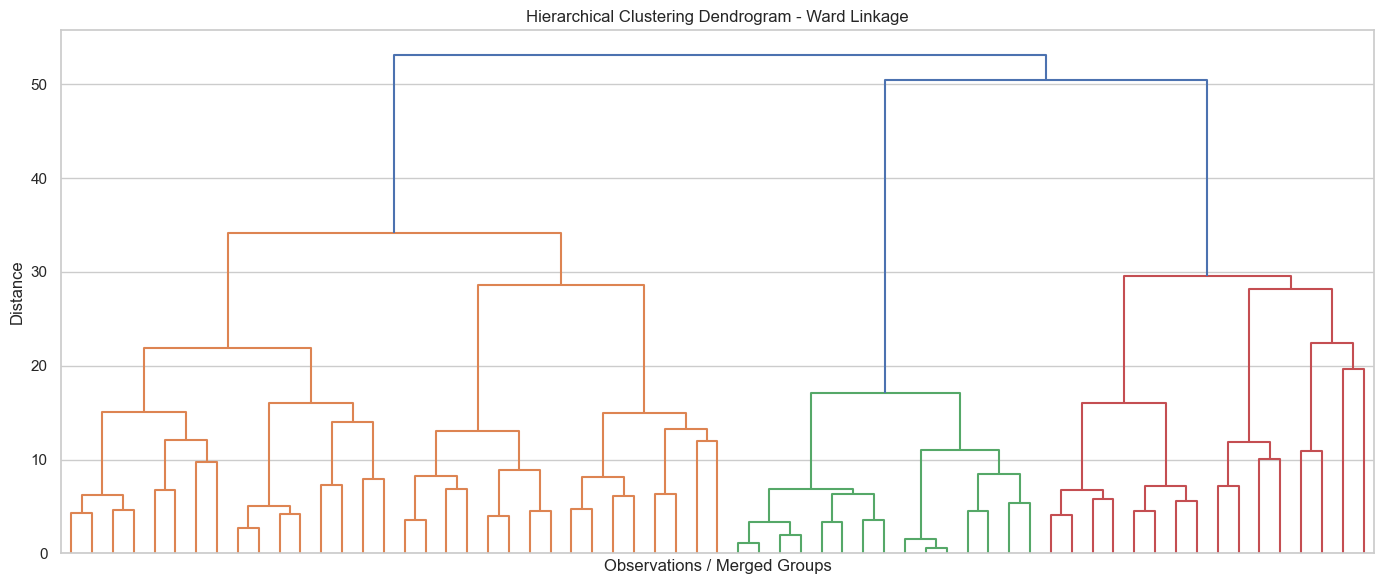

In [33]:
DENDROGRAM_SAMPLE_SIZE = 1000

dendro_rng = np.random.default_rng(RANDOM_STATE)

dendro_indices = dendro_rng.choice(
    len(X_cluster),
    size=DENDROGRAM_SAMPLE_SIZE,
    replace=False
)

X_dendro = X_cluster[dendro_indices]

Z = linkage(
    X_dendro,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="level",
    p=5,
    no_labels=True
)

plt.title(
    "Hierarchical Clustering Dendrogram - Ward Linkage"
)

plt.xlabel("Observations / Merged Groups")
plt.ylabel("Distance")

plt.tight_layout()
plt.show()

## Dendrogram Observation

The dendrogram shows how individual observations and groups of observations are progressively merged during Agglomerative Hierarchical Clustering using Ward linkage.
The vertical axis represents the linkage distance at which clusters are merged. Larger vertical gaps between successive merges may indicate potential divisions in the hierarchical structure.
The dendrogram is generated using a sample of 1,000 observations to make the visualization easier to interpret. It helps us understand the hierarchical merging pattern and identify a possible number of clusters.
The final number of clusters is selected by considering the dendrogram together with the clustering evaluation metrics.

##  Final Agglomerative Hierarchical Model

Ward linkage is used for the final Agglomerative Hierarchical Clustering
model.
The same value of K and the same comparison sample used for K-Means are
used so that the algorithms can be compared consistently.

In [34]:
agg_model = AgglomerativeClustering(
    n_clusters=K,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(
    X_cluster
)

print("Agglomerative Hierarchical Clustering completed.")
print("Number of clusters:", K)

Agglomerative Hierarchical Clustering completed.
Number of clusters: 3


##  Agglomerative Clustering Evaluation

The final Agglomerative Hierarchical Clustering model is evaluated using
the Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.

In [35]:
agg_silhouette = silhouette_score(
    X_cluster,
    agg_labels
)

agg_db = davies_bouldin_score(
    X_cluster,
    agg_labels
)

agg_ch = calinski_harabasz_score(
    X_cluster,
    agg_labels
)

agg_metrics = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ],
    "Agglomerative Hierarchical": [
        agg_silhouette,
        agg_db,
        agg_ch
    ]
})

display(agg_metrics.round(4))

,Metric,Agglomerative Hierarchical
0,Silhouette Score,0.1681
1,Davies-Bouldin Index,1.9583
2,Calinski-Harabasz Index,500.2212


#  PCA Visualization — Agglomerative Hierarchical Clustering

PCA is used to represent the Agglomerative clusters in two dimensions.
The colours represent the cluster assigned to each Airbnb listing.

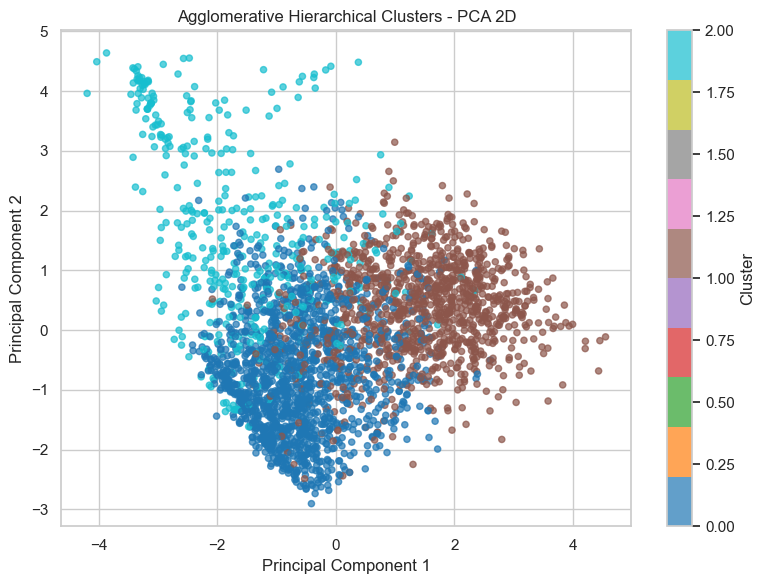

In [37]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap="tab10",
    s=20,
    alpha=0.7
)

plt.title(
    "Agglomerative Hierarchical Clusters - PCA 2D"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

## PCA Observation — Agglomerative Hierarchical Clustering

The PCA plot shows the clusters formed using Ward linkage. The first two principal components explain 42.80% of the total variance. The plot helps observe cluster separation and overlap, but clustering quality must also be evaluated using the performance metrics.

#  t-SNE Visualization

t-SNE is used as an additional non-linear dimensionality reduction
technique.
It attempts to preserve local neighbourhood relationships when representing
high-dimensional observations in two dimensions.
Because t-SNE is computationally expensive, a smaller sample is used.

In [40]:
TSNE_SAMPLE_SIZE = 1500

tsne_rng = np.random.default_rng(RANDOM_STATE)

tsne_indices = tsne_rng.choice(
    len(X_cluster),
    size=TSNE_SAMPLE_SIZE,
    replace=False
)

X_tsne_input = X_cluster[tsne_indices]

tsne_labels = kmeans_labels[tsne_indices]

print("t-SNE sample shape:", X_tsne_input.shape)

t-SNE sample shape: (1500, 16)


In [41]:
tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000
)

X_tsne = tsne.fit_transform(
    X_tsne_input
)

print("t-SNE completed.")

t-SNE completed.


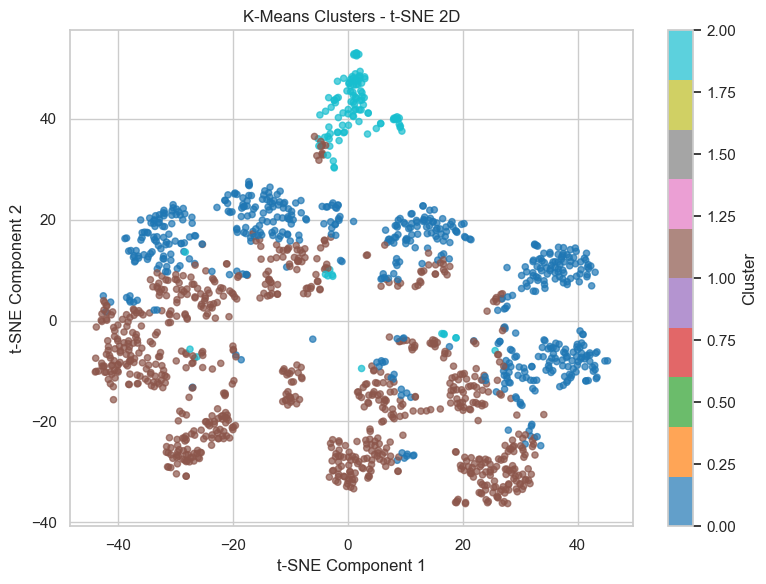

In [42]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=tsne_labels,
    cmap="tab10",
    s=20,
    alpha=0.7
)

plt.title("K-Means Clusters - t-SNE 2D")

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()
plt.show()

## t-SNE Observation

The t-SNE visualization provides a two-dimensional representation of the K-Means clusters, helping us explore the local patterns in the processed dataset. Each colour represents a different cluster.
The plot can be examined to identify groupings and overlap between the clusters. However, t-SNE is mainly used for visualization, and the distances between groups should not be treated as a definitive measure of clustering quality.
Therefore, the observations from this plot should be considered alongside the PCA visualization and the clustering evaluation metrics.

#  Final Clustering Comparison

The final comparison table presents the performance of K-Means and
Agglomerative Hierarchical Clustering using the three mandatory clustering
evaluation metrics.
Both algorithms were evaluated using the same preprocessed comparison
sample and the same number of clusters.

In [43]:
comparison_df = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Agglomerative Hierarchical"
    ],
    
    "Silhouette Score": [
        kmeans_silhouette,
        agg_silhouette
    ],
    
    "Davies-Bouldin Index": [
        kmeans_db,
        agg_db
    ],
    
    "Calinski-Harabasz Index": [
        kmeans_ch,
        agg_ch
    ]
})

display(comparison_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.2099,1.6399,628.1446
1,Agglomerative Hierarchical,0.1681,1.9583,500.2212


##  Cluster Size Comparison

The number of observations in each cluster is examined for both algorithms.
This helps identify whether the clustering algorithms produce very small
or highly imbalanced clusters.

In [44]:
cluster_size_comparison = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Agglomerative Hierarchical":
        pd.Series(agg_labels).value_counts().sort_index()
})

cluster_size_comparison.index.name = "Cluster"

display(cluster_size_comparison)

,K-Means,Agglomerative Hierarchical
Cluster,,
0,1164,1479
1,1624,1097
2,212,424


#  Cluster Profiling

After clustering, the original Airbnb variables are examined to understand
the characteristics of each discovered cluster.
This profiling is performed after the clustering process and does not
influence the formation of the clusters.

In [45]:
profile = df_cluster.copy()

profile["KMeans_Cluster"] = kmeans_labels
profile["Agglomerative_Cluster"] = agg_labels

cluster_profile = profile.groupby(
    "KMeans_Cluster"
)[
    [
        "latitude",
        "longitude",
        "price",
        "minimum_nights",
        "number_of_reviews",
        "reviews_per_month",
        "calculated_host_listings_count",
        "availability_365"
    ]
].mean().round(2)

display(cluster_profile)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
KMeans_Cluster,,,,,,,,
0,40.73,-73.94,130.87,3.08,57.43,2.45,2.33,168.67
1,40.73,-73.96,154.35,5.81,3.86,0.34,1.49,59.44
2,40.74,-73.97,262.73,46.19,2.91,0.54,88.91,266.35


In [46]:
room_type_profile = pd.crosstab(
    profile["KMeans_Cluster"],
    profile["room_type"],
    normalize="index"
).round(3)

display(room_type_profile)

room_type,Entire home/apt,Private room,Shared room
KMeans_Cluster,,,
0,0.454,0.510,0.036
1,0.509,0.469,0.023
2,0.745,0.222,0.033


In [47]:
neighbourhood_profile = pd.crosstab(
    profile["KMeans_Cluster"],
    profile["neighbourhood_group"],
    normalize="index"
).round(3)

display(neighbourhood_profile)

neighbourhood_group,Bronx,Brooklyn,Manhattan,Queens,Staten Island
KMeans_Cluster,,,,,
0,0.034,0.442,0.353,0.163,0.008
1,0.014,0.438,0.466,0.076,0.006
2,0.005,0.118,0.792,0.085,0.000


# Final Interpretation

The Airbnb NYC 2019 dataset was analysed using unsupervised machine learning to identify groups of listings with similar characteristics. The selected features include location, room type, price, minimum nights, review activity, host listing count, and availability.

K-Means and Agglomerative Hierarchical Clustering were applied to the processed data to explore different clustering patterns.
